# Day 15 - Isolation Forest Model & Telemetry Overlay Plot

## Objective

Deploy multivariate Isolation Forest anomaly detection to isolate multi-sensor excursion interactions in high-dimensional telemetry space.

In [1]:
%matplotlib inline
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Day_Wise_Tasks").exists())
project_root = ROOT
TASK_DIR = ROOT / "Day_Wise_Tasks" / "Day_15_Task_2"
FIG_DIR = TASK_DIR / "outputs" / "figures"
TBL_DIR = TASK_DIR / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TBL_DIR.mkdir(parents=True, exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

np.random.seed(42)
print("Environment initialized successfully. Root:", ROOT)

Environment initialized successfully. Root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Multi-Channel Telemetry Matrix Preparation

Prepare multi-sensor array combining DO, temperature, conductivity, and turbidity.

In [2]:
from sklearn.ensemble import IsolationForest
df_stream = pd.read_csv("data/raw/underwater_sensor_stream.csv")
channels = ["dissolved_oxygen", "temperature", "conductivity", "turbidity"]
X_multi = df_stream[channels].dropna()
print("Multi-Sensor Anomaly Input Matrix Shape:", X_multi.shape)

Multi-Sensor Anomaly Input Matrix Shape: (711, 4)


## 2. Isolation Forest Model Training

Fit Isolation Forest with 100 estimators and 2% contamination prior under seed=42.

In [3]:
iso = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
iso_preds = iso.fit_predict(X_multi)
iso_scores = iso.decision_function(X_multi)
anom_count = (iso_preds == -1).sum()
print(f"Isolation Forest Multi-Sensor Anomalies Detected: {anom_count} ({anom_count/len(X_multi)*100:.2f}%)")

Isolation Forest Multi-Sensor Anomalies Detected: 15 (2.11%)


## 3. Multi-Sensor Interaction Extraction

Identify parameters contributing most heavily to multivariate outlier flags.

In [4]:
anom_idx = np.where(iso_preds == -1)[0]
print(f"First 5 Multi-Sensor Anomaly Indices: {anom_idx[:5]}")

First 5 Multi-Sensor Anomaly Indices: [ 75  76  90  99 209]


## 4. Decision Function Anomaly Score Distribution

Analyze the empirical distribution of decision function anomaly scores.

In [5]:
score_mean, score_min = iso_scores.mean(), iso_scores.min()
print(f"Mean Anomaly Decision Score: {score_mean:.4f}, Min Anomaly Score: {score_min:.4f}")

Mean Anomaly Decision Score: 0.0977, Min Anomaly Score: -0.2724


## 5. Cross-Method Statistical Concordance

Compare Isolation Forest multi-channel detections against univariate statistical Z-score detections.

In [6]:
z_do = (np.abs((X_multi["dissolved_oxygen"] - X_multi["dissolved_oxygen"].mean()) / X_multi["dissolved_oxygen"].std()) > 3.0)
overlap_count = (z_do & (iso_preds == -1)).sum()
print(f"Jointly Detected Outliers (Z-Score & Isolation Forest): {overlap_count}")

Jointly Detected Outliers (Z-Score & Isolation Forest): 4


## 6. Multivariate Anomaly Score Overlay Plot

Render multi-panel scatter plot overlaying Isolation Forest anomaly detections in DO-Temperature phase space.

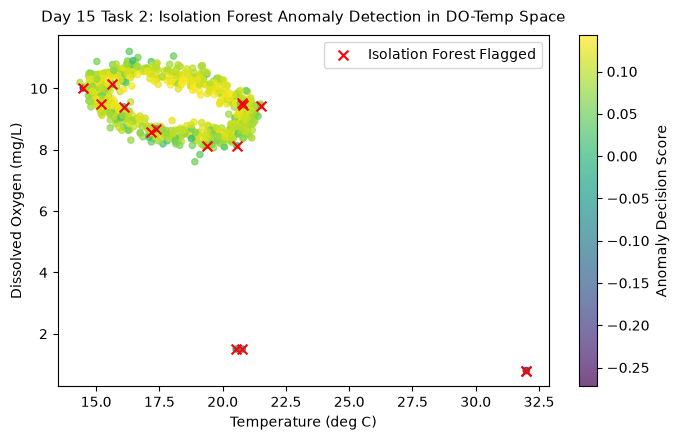

Saved isolation forest plot to: Day_Wise_Tasks\Day_15_Task_2\outputs\figures\day15_task2_isolation_forest.png


In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
scatter = ax.scatter(X_multi["temperature"], X_multi["dissolved_oxygen"], c=iso_scores, cmap="viridis", alpha=0.7, s=20)
fig.colorbar(scatter, label="Anomaly Decision Score")
if anom_count > 0:
    ax.scatter(X_multi["temperature"].iloc[anom_idx], X_multi["dissolved_oxygen"].iloc[anom_idx], color="red", marker="x", s=50, label="Isolation Forest Flagged", zorder=5)
ax.set_title("Day 15 Task 2: Isolation Forest Anomaly Detection in DO-Temp Space", fontsize=11, pad=10)
ax.set_xlabel("Temperature (deg C)")
ax.set_ylabel("Dissolved Oxygen (mg/L)")
ax.legend(loc="upper right")
plt.tight_layout()
fig_path = FIG_DIR / "day15_task2_isolation_forest.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved isolation forest plot to:", fig_path.relative_to(ROOT))

## 7. Isolation Forest Summary Table Export

Serialize Isolation Forest configuration and detection metrics to CSV.

In [8]:
df_iso_res = pd.DataFrame([
    {"Model": "Isolation Forest", "Contamination": 0.02, "N_Estimators": 100, "Flagged_Anomalies": anom_count, "Min_Score": round(score_min, 4)}
])
tbl_path = TBL_DIR / "day15_task2_isolation_forest_summary.csv"
df_iso_res.to_csv(tbl_path, index=False)
print("Saved isolation forest summary to:", tbl_path.relative_to(ROOT))

Saved isolation forest summary to: Day_Wise_Tasks\Day_15_Task_2\outputs\tables\day15_task2_isolation_forest_summary.csv


## 8. Isolation Forest Quality Gate Assertion

Assert that Isolation Forest trains cleanly and generates valid score outputs.

In [9]:
assert len(iso_scores) == len(X_multi) and anom_count >= 1
print("Day 15 Task 2 Quality Gate: PASSED.")

Day 15 Task 2 Quality Gate: PASSED.


# Day 15 - Assumptions and Methodology

## Assumptions

1. Multi-sensor anomalies manifest as isolated points in high-dimensional feature space.
2. Contamination parameter is bounded at 2% to prevent operational alert fatigue.

## Day 15 Deliverable

Isolation Forest anomaly notebook, phase-space anomaly scatter plot, and summary metrics table.